## Test training


In [ ]:
%load_ext autoreload
%autoreload 1

import os
os.environ["QUANTDATA_ROOT"] = "/mnt/c/Users/Public/quantdata"

from cdxcore.verbose import Context
verbose = Context("all")
with verbose.write_t("Importing torch...", end='') as tme:   
    import torch
    verbose.write(f"done; this took {tme}.", head=False)

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.torch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler

from quantdata.dysanos.simple.sampler import SimpleSampler, SimpleConfig, SamplingConfig, ExpiryFilter, RawDayFilter, SampleDaysConfig, DateRange, PoolConfig
from cdxcore.verbose import Context
from datetime import date

def test():
    simple_config = SimpleConfig(
            tickers = ['SPX','NDX','RUT'],
            date_range = DateRange(start=date(2015, 1, 1), end=date(2025, 7, 1)),
            raw_day_filter = RawDayFilter(),
            expiry_filter = ExpiryFilter(),
            sample_days_config = SampleDaysConfig(),
            sampling_config = SamplingConfig(num_samples=20)
    )
    pool_config = PoolConfig(num_workers=4, threading=False) # no parallel processing for testing
    verbose = Context.all
    refresh_cache = False

    sampler = SimpleSampler(simple_config=simple_config, pool_config=pool_config, refresh_cache=refresh_cache, verbose=verbose)
    return sampler

sampler = test()
print("/done")

## Training a simple MLP

/model created.
01:   Trainer for 'AEC viz_train2 0f5837ec6b870a6d' on data 0f5837ec6b870a6d
01:   ======================================================================
02:     Restoring checkpoint from '/tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train2 366c8e1a/last.pt'... done; this took 0.14s.
02:     Model is ready. Current epoch to train is 28.
01:   Launching 'AEC viz_train2 0f5837ec6b870a6d' training for 1000 epochs over 1233 training and 309 validation samples, using a mini bastch size of 16 for 10 batches per epoch, and a batch size of 64 for valuation. The model has 31809 parameters. Resuming from epoch 28.
01:   Training 'viz_train2' epoch 29/1000 error avg trn 0.00246; val 0.002519/0.004405 [2s 3s 0.89s]. LR: 7.23e-04, GN 0.004784, excess: 0.003513/0.005536. ETA: 1:59:29.


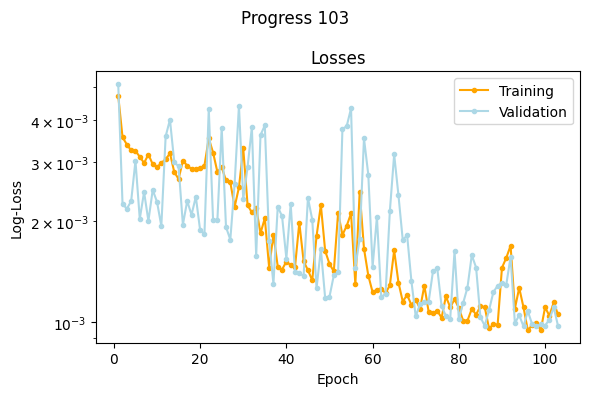

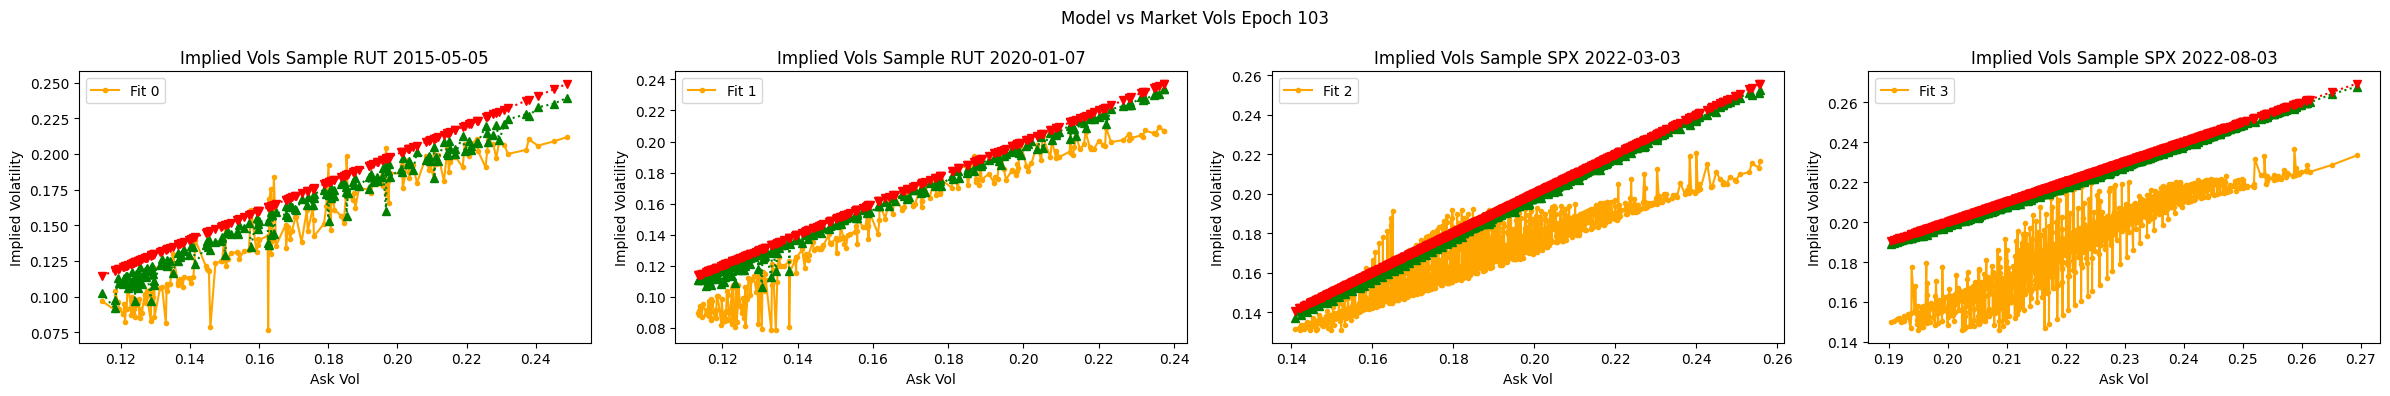

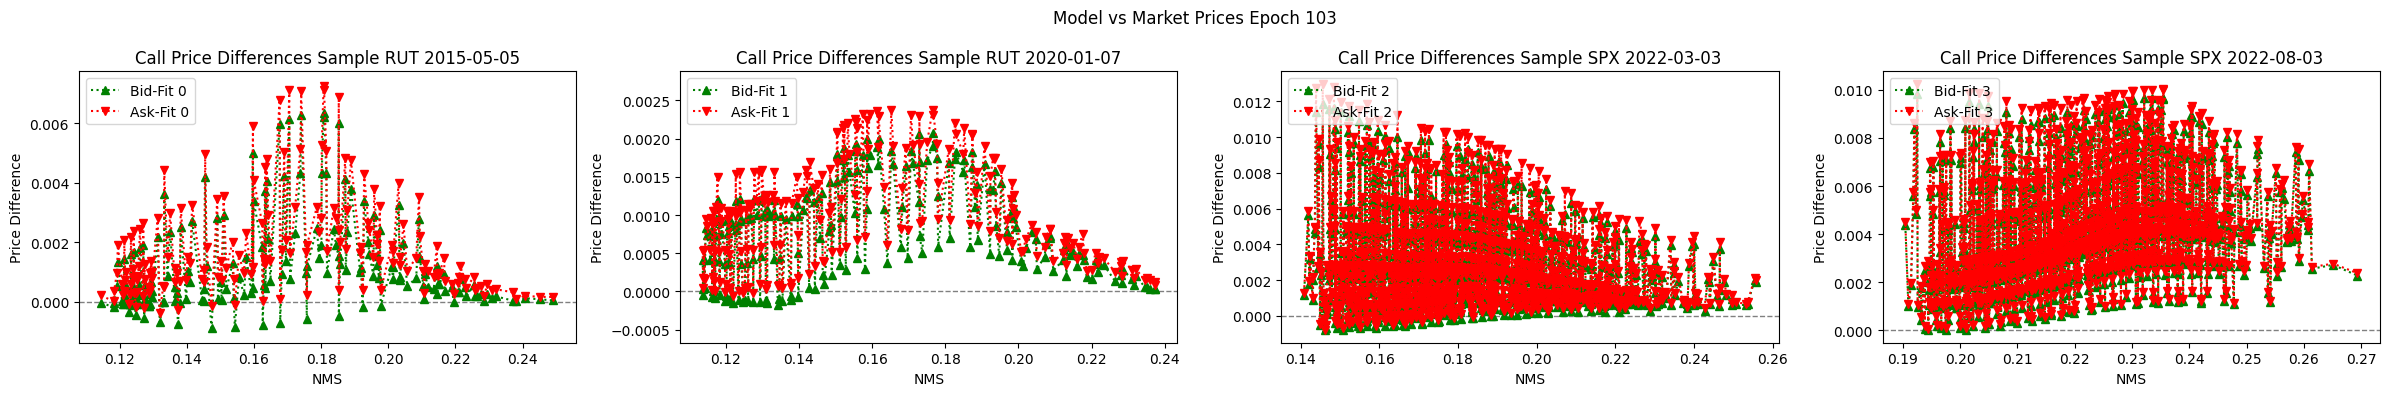

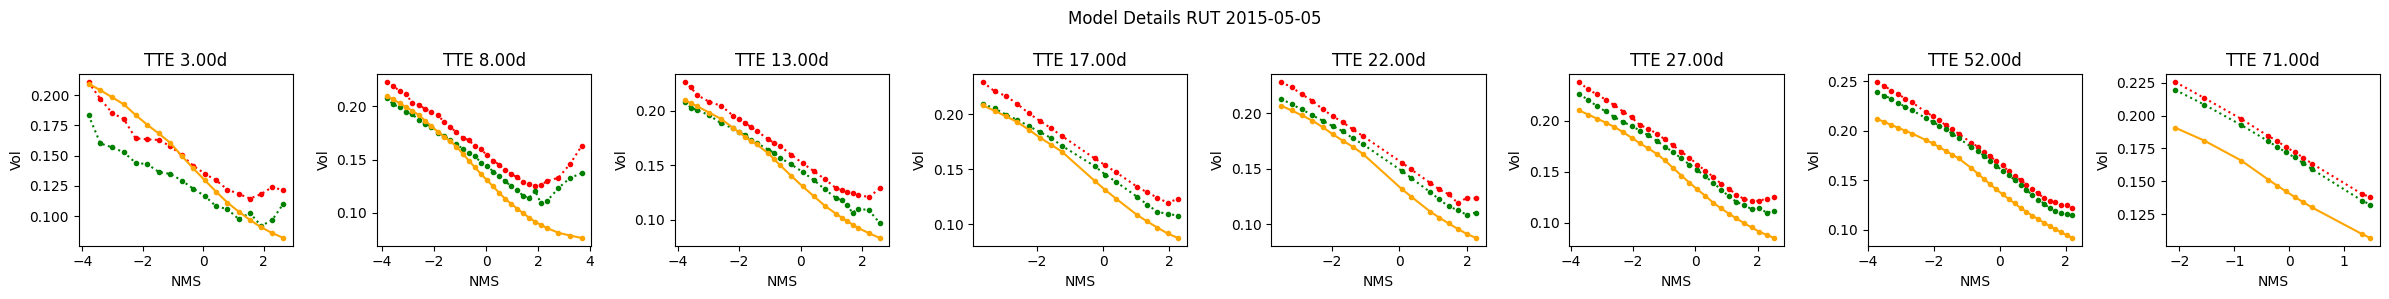

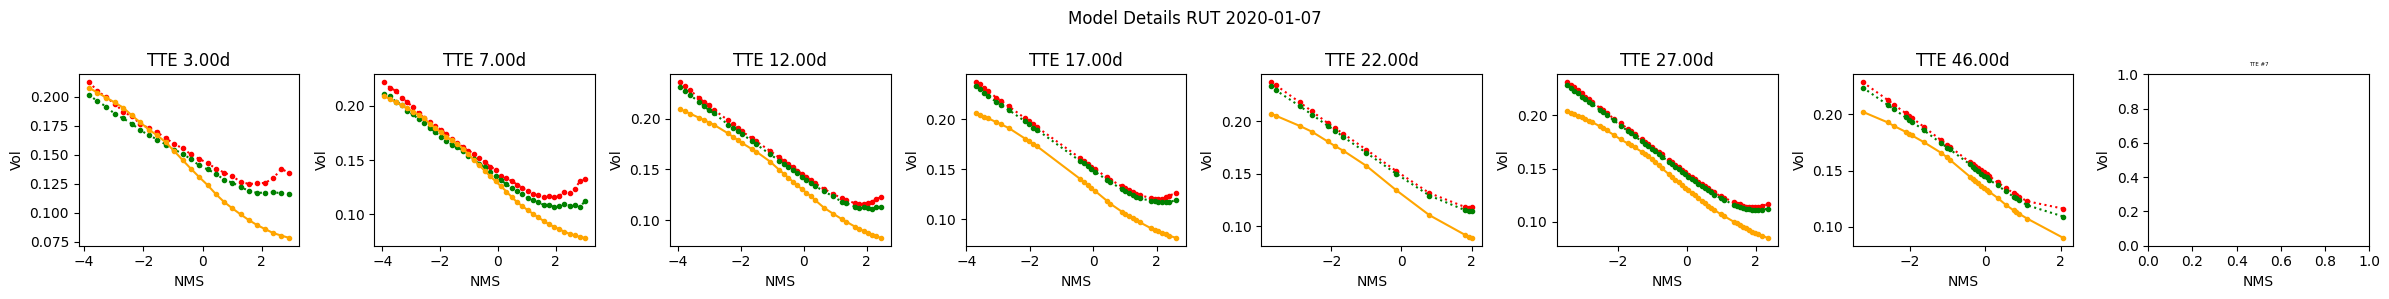

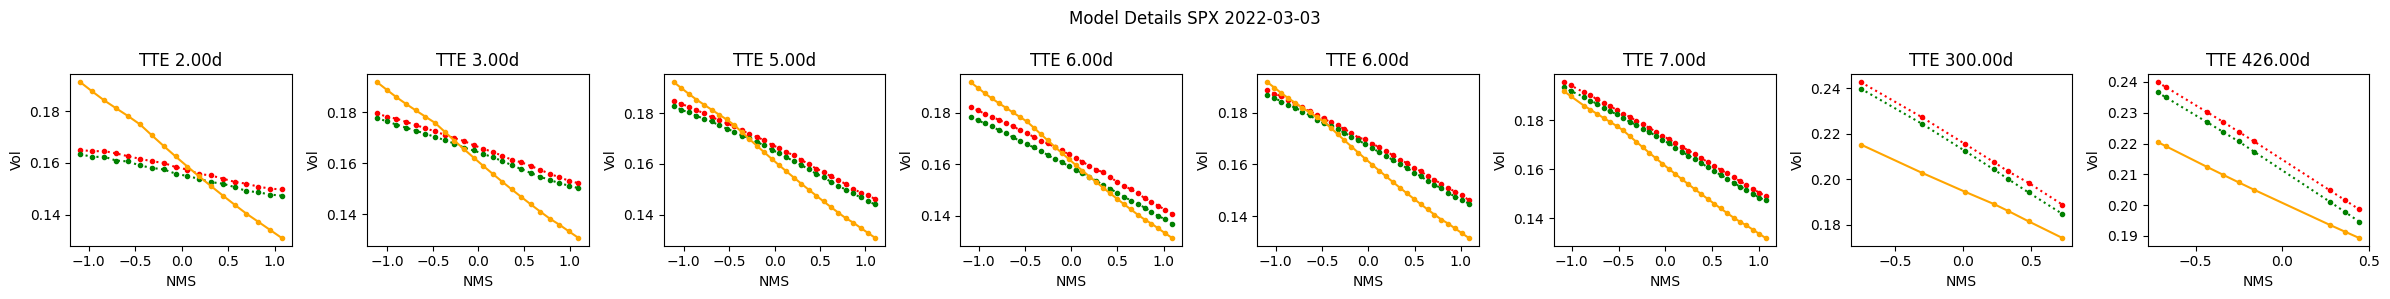

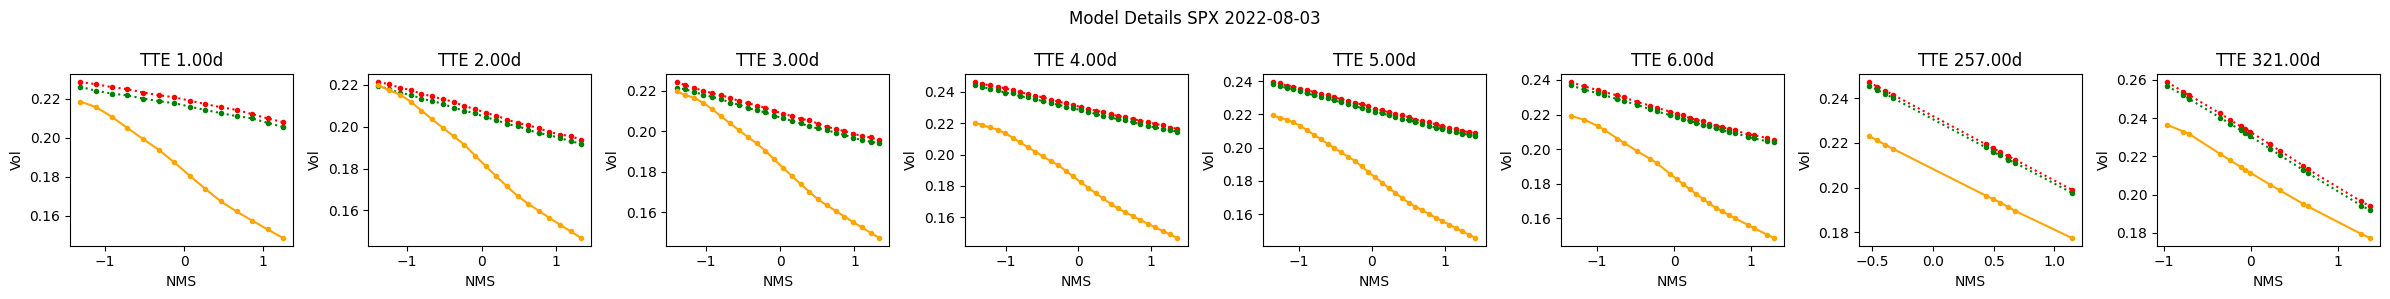

02:     Saving checkpoint to /tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train2 366c8e1a/last.pt... done; this took 0.086s.
01:   Training 'viz_train2' epoch 30/1000 error avg trn 0.00283; val 0.003288/0.002323 [2s 3s 0.83s]. LR: 7.18e-04, GN 0.00257, excess: 0.006186/0.004633. ETA: 4:52:04.
02:     Saving checkpoint to /tmp/chkp/quantdata/dysanos/0f5837ec6b870a6d/viz_train2 366c8e1a/last.pt... done; this took 0.089s.
01:   Training 'viz_train2' epoch 31/1000 error avg trn 0.002952; val 0.002232/0.002894 [2s 3s 0.86s]. LR: 7.13e-04, GN 0.004314, excess: 0.003335/0.003796. ETA: 7:45:34.
01:   Training 'viz_train2' epoch 32/1000 error avg trn 0.002145; val 0.002121/0.003807 [2s 3s 0.85s]. LR: 7.08e-04, GN 0.0007067, excess: 0.003047/0.004957. ETA: 10:42:51.
01:   Training 'viz_train2' epoch 33/1000 error avg trn 0.002075; val 0.002187/0.001571 [2s 3s 0.86s]. LR: 7.03e-04, GN 0.004322, excess: 0.004014/0.002594. ETA: 13:33:06.
01:   Training 'viz_train2' epoch 34/1000 error avg trn 0

In [ ]:
# reloader

%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.block_sampler
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer

from quantdata.dysanos.simple.model import AEC, BaseEnvironment, FeedForward
from quantdata.dysanos.simple.trainer import Trainer, TrainConfig
from cdxcore.subdir import SubDir
import ipynbname

env   = BaseEnvironment(device="cuda", debug=False)

aec_config = AEC.Config(
    num_state = 32,
    num_compress = 128   ,
    encode_what = "vol",
    mid_fit_weight = 0.1,
    fit_average = True,
    encoder_set_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    encoder_fix_config = FeedForward.Config(
        num_depth = 2,
        num_width = 64,
        activation = 'ReLU',
    ),
    decoder_config = FeedForward.Config(
        num_depth = 2,
        num_width = 32,
        activation = 'ReLU',
    ),
    vizualizer_config = AEC.VisualizerConfig(details=True)  # set to None to turn off visualization
)

model = AEC(env=env, 
            shapes=sampler.shapes(), 
            stats=sampler.stats,
            num_steps=sampler.num_steps,
            max_options=sampler.max_options,
            config=aec_config )

print("/model created.")

train_config = TrainConfig(
    lr_init = 1E-3,
)

checkpoint = SubDir("!/chkp/quantdata/dysanos")

trainer = Trainer( label=ipynbname.name(), model=model, sampler=sampler, config=train_config, verbose=verbose(1), path=checkpoint )
_ = trainer(epochs=1000)
